# 🔀 True Hybrid Recommender — Thử Nghiệm & Phân Tích

**IT Job Market Intelligence Platform**

Notebook này thực hiện thử nghiệm **True Hybrid Recommendation System** — kết hợp 3 nguồn tri thức:

| Thành phần | Trọng số | Mô tả |
|---|---|---|
| **Semantic NLP** (SentenceTransformer 384d) | 45% | Hiểu ngữ cảnh nghề nghiệp, kinh nghiệm từ CV |
| **Skill Overlap** (Jaccard Match) | 30% | Đảm bảo kỹ năng cốt lõi được đáp ứng |
| **Collaborative Filtering** (TruncatedSVD) | 25% | Khai thác hành vi ứng tuyển cộng đồng |

$$\text{Hybrid Score} = 0.45 \times \text{Semantic} + 0.30 \times \text{Skills} + 0.25 \times \text{CF}$$

---

## 0. Thiết lập môi trường

In [3]:
import os, sys, json

# Tự động tìm thư mục gốc dự án (chứa thư mục 'src')
def get_project_root():
    curr = os.path.abspath(os.getcwd())
    while curr != os.path.dirname(curr):
        if os.path.exists(os.path.join(curr, 'src')):
            return curr
        curr = os.path.dirname(curr)
    return os.path.abspath(os.path.join(os.getcwd(), '..', '..'))

PROJECT_ROOT = get_project_root()
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print("Project root:", PROJECT_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_colwidth', 60)

print("✅ Import thành công!")

Project root: c:\Users\Minh Doan\repo_github\IT-Job-Market-Intelligence
✅ Import thành công!


## 1. Trích Xuất Kỹ Năng Ứng Viên (Skill Extractor)

In [4]:
from src.recommender.matcher import extract_candidate_skills, infer_persona_from_skills

# Hồ sơ thử nghiệm
SAMPLE_PROFILES = {
    "Java Backend": """Kỹ sư Backend 2 năm kinh nghiệm Java Spring Boot, Microservices, PostgreSQL, Redis, Docker, 
                       REST API. Có kinh nghiệm CI/CD với Jenkins, Kubernetes trên AWS.""",
    "React Frontend": """Frontend Developer thành thạo React, TypeScript, Next.js, HTML5, CSS3, TailwindCSS, 
                         Figma, Webpack. Kinh nghiệm kết nối GraphQL và REST API.""",
    "Data Analyst": """Fresher Data Analyst có kiến thức Python (Pandas, NumPy, Matplotlib), SQL, Power BI,
                       Excel nâng cao. Đã thực hiện phân tích EDA và xây dựng dashboard báo cáo.""",
    "DevOps Engineer": """DevOps Engineer 3 năm, chuyên AWS, GCP, Terraform, Ansible, Docker, Kubernetes,
                          Prometheus, Grafana, Jenkins CI/CD, Linux system administration.""",
    "AI/ML Engineer": """ML Engineer có kinh nghiệm PyTorch, TensorFlow, scikit-learn, Hugging Face transformers,
                          fine-tuning LLM, Python, FastAPI, Docker, MLflow model serving.""",
}

print("Kết quả trích xuất kỹ năng từ hồ sơ:")
print("="*70)
skill_results = {}
for name, profile in SAMPLE_PROFILES.items():
    skills = extract_candidate_skills(profile)
    persona = infer_persona_from_skills(skills)
    skill_results[name] = {'skills': skills, 'persona': persona}
    print(f"[{name}]")
    print(f"  Kỹ năng nhận diện : {skills}")
    print(f"  Persona suy luận  : {persona['name']} ({persona['id']})")
    print()

c:\Users\Minh Doan\repo_github\IT-Job-Market-Intelligence\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Kết quả trích xuất kỹ năng từ hồ sơ:
[Java Backend]
  Kỹ năng nhận diện : ['AWS', 'CI/CD', 'Docker', 'Java', 'Kubernetes', 'Microservices', 'PostgreSQL', 'Redis', 'Spring Boot']
  Persona suy luận  : Kỹ Sư Backend (Java / Microservices) (backend_java)

[React Frontend]
  Kỹ năng nhận diện : ['HTML/CSS', 'JavaScript', 'Next.js', 'React', 'Tailwind CSS', 'TypeScript']
  Persona suy luận  : Kỹ Sư Frontend (React / TypeScript) (frontend_react)

[Data Analyst]
  Kỹ năng nhận diện : ['NumPy', 'Pandas', 'Python', 'SQL']
  Persona suy luận  : Kỹ Sư Dữ Liệu & Phân Tích (Data Platform / SQL) (data_engineer)

[DevOps Engineer]
  Kỹ năng nhận diện : ['AWS', 'Ansible', 'CI/CD', 'Docker', 'GCP', 'Kubernetes', 'Linux', 'Terraform']
  Persona suy luận  : Kỹ Sư DevOps & Điện Toán Đám Mây (K8s / AWS) (devops_cloud)

[AI/ML Engineer]
  Kỹ năng nhận diện : ['Docker', 'FastAPI', 'LLM', 'Machine Learning', 'PyTorch', 'Python', 'TensorFlow']
  Persona suy luận  : Kỹ Sư AI & Machine Learning (PyTorch / NLP / 

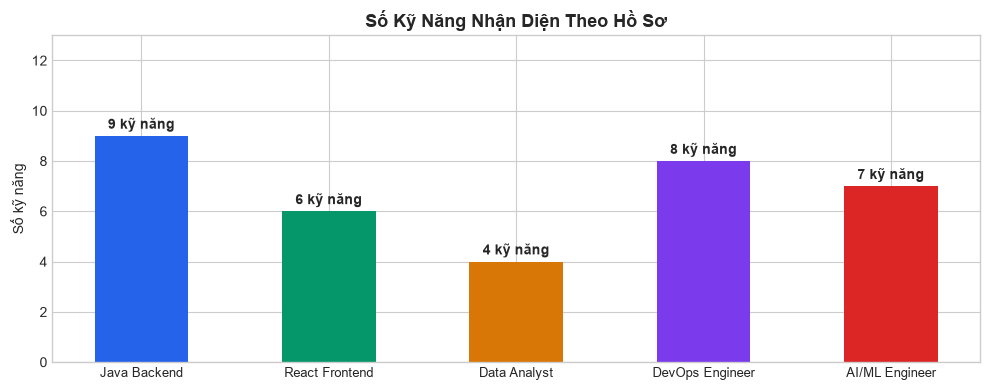

In [5]:
# Trực quan hóa số kỹ năng nhận diện
names = list(skill_results.keys())
counts = [len(v['skills']) for v in skill_results.values()]

fig, ax = plt.subplots(figsize=(10, 4))
colors = ['#2563eb', '#059669', '#d97706', '#7c3aed', '#dc2626']
bars = ax.bar(names, counts, color=colors, width=0.5)
ax.bar_label(bars, fmt='%d kỹ năng', padding=3, fontsize=10, fontweight='bold')
ax.set_title('Số Kỹ Năng Nhận Diện Theo Hồ Sơ', fontsize=13, fontweight='bold')
ax.set_ylabel('Số kỹ năng')
ax.set_ylim(0, max(counts) + 4)
ax.tick_params(axis='x', labelsize=9)
plt.tight_layout()
plt.show()

## 2. Thành Phần Ngữ Nghĩa — Semantic NLP (384d Vector)

In [6]:
from src.embeddings.generator import get_embedding_model, load_embeddings_and_metadata

print("Đang nạp SentenceTransformer model và embeddings...")
model = get_embedding_model()
embeddings_matrix, metadata_list = load_embeddings_and_metadata()

print(f"✅ Model: paraphrase-multilingual-MiniLM-L12-v2")
print(f"Số vector việc làm: {embeddings_matrix.shape[0]:,}")
print(f"Số chiều embedding : {embeddings_matrix.shape[1]}")

Đang nạp SentenceTransformer model và embeddings...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6683.75it/s]


✅ Model: paraphrase-multilingual-MiniLM-L12-v2
Số vector việc làm: 2,821
Số chiều embedding : 384


Đang encode các hồ sơ mẫu thành vector 384 chiều...
✅ Shape: (5, 384)


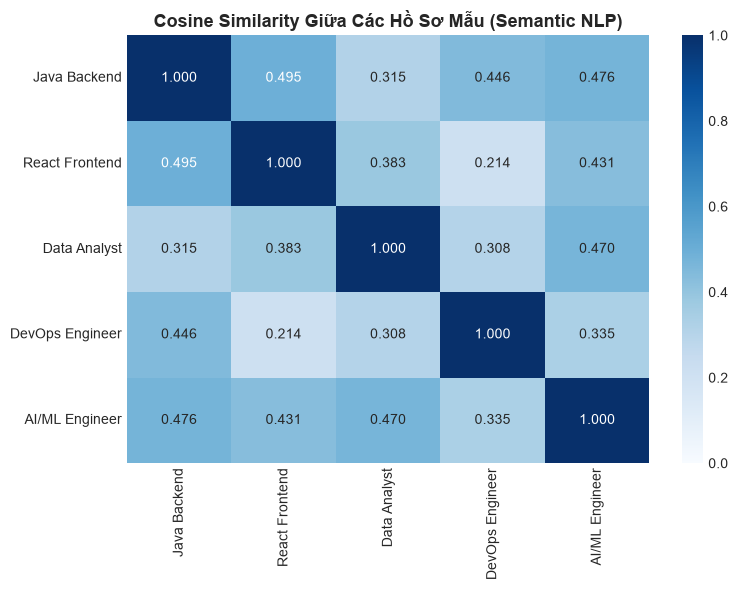

In [7]:
# Encode tất cả hồ sơ mẫu
profile_texts = list(SAMPLE_PROFILES.values())
profile_names = list(SAMPLE_PROFILES.keys())

print("Đang encode các hồ sơ mẫu thành vector 384 chiều...")
candidate_vectors = model.encode(profile_texts, normalize_embeddings=True)
print(f"✅ Shape: {candidate_vectors.shape}")

# Tính cosine similarity giữa các hồ sơ mẫu với nhau
inter_sim = cosine_similarity(candidate_vectors)

fig, ax = plt.subplots(figsize=(8, 6))
im = sns.heatmap(inter_sim, xticklabels=profile_names, yticklabels=profile_names,
                  annot=True, fmt='.3f', cmap='Blues', ax=ax, vmin=0, vmax=1)
ax.set_title('Cosine Similarity Giữa Các Hồ Sơ Mẫu (Semantic NLP)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [8]:
# Top 5 việc làm phù hợp nhất về ngữ nghĩa cho từng hồ sơ
print("Top 5 việc làm theo Semantic Similarity:\n")
for i, (name, vec) in enumerate(zip(profile_names, candidate_vectors)):
    sims = cosine_similarity(vec.reshape(1, -1), embeddings_matrix)[0]
    top5_idx = np.argsort(sims)[::-1][:5]
    print(f"[{name}]")
    for rank, idx in enumerate(top5_idx, 1):
        meta = metadata_list[idx]
        print(f"  #{rank} {meta['title'][:45]:<45}  sim={sims[idx]:.4f}  [{meta['city']}]")
    print()

Top 5 việc làm theo Semantic Similarity:

[Java Backend]
  #1 Java Developer (>5 YOE)                        sim=0.7579  [Hồ Chí Minh]
  #2 Trưởng Nhóm Java                               sim=0.7536  [Hà Nội]
  #3 Trưởng Nhóm Java Developer                     sim=0.7322  [Hà Nội]
  #4 Chuyên Viên Kỹ Thuật Phần Mềm Java             sim=0.7295  [Hà Nội]
  #5 Java Developer                                 sim=0.7290  [Hà Nội]

[React Frontend]
  #1 Frontend Developer (ReactJS, NextJS, TypeScri  sim=0.7624  [Hồ Chí Minh]
  #2 Lập Trình Web Full Stack Nodejs, PHP           sim=0.7228  [Hồ Chí Minh]
  #3 Trưởng Phòng Fullstack Developer/ Kỹ Sư Full   sim=0.7137  [Hồ Chí Minh]
  #4 Fullstack Developer                            sim=0.7092  [Hà Nội]
  #5 Web Developer (Backend/Fullstack)              sim=0.7054  [Hà Nội]

[Data Analyst]
  #1 Fresher Data Analyst (F21                      sim=0.8088  [Hà Nội]
  #2 Middle Data Analyst (Từ 2 Năm Kinh Nghiệm)     sim=0.7852  [Hà Nội]
  #3 Data Ana

## 3. Thành Phần Kỹ Năng — Skill Overlap Score

In [9]:
# Tính Skill Score cho từng hồ sơ
def compute_skill_score(candidate_skills: list, job_skills: list) -> float:
    """Jaccard-style: số kỹ năng trùng / tổng kỹ năng yêu cầu của job."""
    cand_set = set(candidate_skills)
    job_set  = set(job_skills)
    if not job_set:
        return 0.5
    if not cand_set:
        return 0.0
    return len(cand_set & job_set) / len(job_set)

# Demo với hồ sơ Java Backend
java_skills = skill_results["Java Backend"]['skills']
print(f"Kỹ năng của hồ sơ Java Backend: {java_skills}")

print("\nSkill Score với 5 job mẫu đầu tiên (có skill info):")
count = 0
for meta in metadata_list:
    job_skills = meta.get('skills', [])
    if job_skills and count < 5:
        score = compute_skill_score(java_skills, job_skills)
        matched = set(java_skills) & set(job_skills)
        print(f"  Job: {meta['title'][:40]:<40}")
        print(f"       Job skills: {job_skills[:5]}")
        print(f"       Trùng     : {sorted(matched)}  → Skill Score = {score:.4f}")
        count += 1

Kỹ năng của hồ sơ Java Backend: ['AWS', 'CI/CD', 'Docker', 'Java', 'Kubernetes', 'Microservices', 'PostgreSQL', 'Redis', 'Spring Boot']

Skill Score với 5 job mẫu đầu tiên (có skill info):
  Job: Full-Stack Web Engineer Intern/Fresher (
       Job skills: ['AWS', 'C#', 'GCP', 'Golang', 'HTML/CSS']
       Trùng     : ['AWS', 'Java', 'PostgreSQL']  → Skill Score = 0.2143
  Job: Kỹ Sư Hệ Thống Nhúng                    
       Job skills: ['C++', 'Linux']
       Trùng     : []  → Skill Score = 0.0000
  Job: UI/UX Designer - Mobile App             
       Job skills: ['Android', 'iOS']
       Trùng     : []  → Skill Score = 0.0000
  Job: Business Analyst - Data Hệ Thống Phân Ph
       Job skills: ['LLM']
       Trùng     : []  → Skill Score = 0.0000
  Job: Junior QA Tester (Manual Testing)       
       Job skills: ['Computer Vision', 'Manual Testing']
       Trùng     : []  → Skill Score = 0.0000


Hồ sơ: Java Backend
  Mean Skill Score : 0.3110
  Skill Score = 1.0: 19 việc làm
  Skill Score > 0.5: 71 việc làm


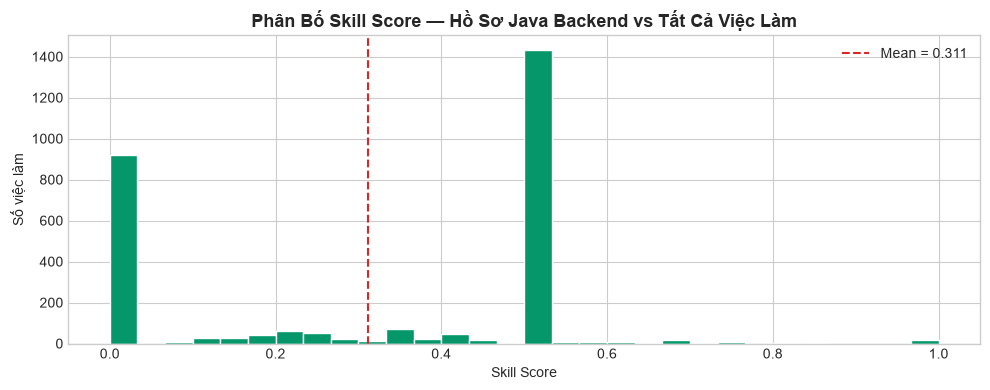

In [10]:
# Phân bố Skill Score cho toàn bộ kho việc làm với hồ sơ Java Backend
all_skill_scores = []
for meta in metadata_list:
    job_skills = meta.get('skills', [])
    score = compute_skill_score(java_skills, job_skills)
    all_skill_scores.append(score)

all_skill_scores = np.array(all_skill_scores)
print(f"Hồ sơ: Java Backend")
print(f"  Mean Skill Score : {all_skill_scores.mean():.4f}")
print(f"  Skill Score = 1.0: {(all_skill_scores == 1.0).sum()} việc làm")
print(f"  Skill Score > 0.5: {(all_skill_scores > 0.5).sum()} việc làm")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(all_skill_scores, bins=30, color='#059669', edgecolor='white')
ax.axvline(all_skill_scores.mean(), color='#dc2626', linestyle='--', label=f'Mean = {all_skill_scores.mean():.3f}')
ax.set_title('Phân Bố Skill Score — Hồ Sơ Java Backend vs Tất Cả Việc Làm', fontsize=13, fontweight='bold')
ax.set_xlabel('Skill Score')
ax.set_ylabel('Số việc làm')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Thành Phần CF — Collaborative Filtering Score

c:\Users\Minh Doan\repo_github\IT-Job-Market-Intelligence\src\recommender\collaborative.py:80: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


-> Nap thanh cong Collaborative Filtering Model (883 jobs).
Persona: backend_java
Số job có CF score : 883
CF Score Min       : 0.6486
CF Score Max       : 0.6839
CF Score Mean      : 0.6521
CF Score Std       : 0.0042


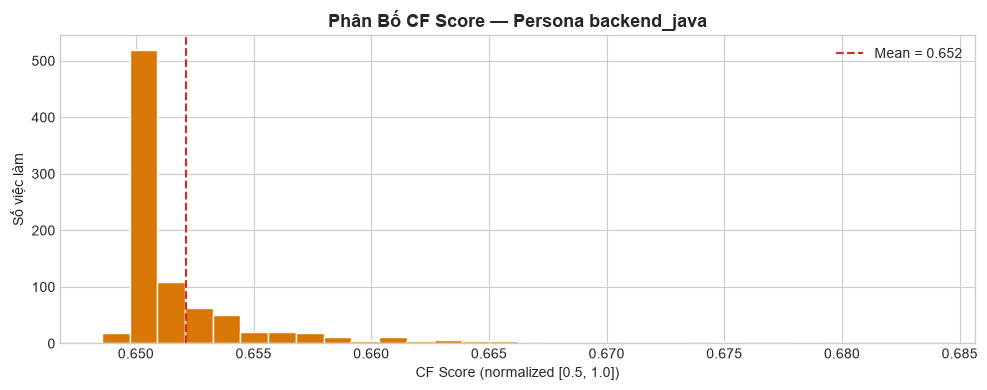

In [11]:
from src.recommender.collaborative import get_cf_recommender

cf_rec = get_cf_recommender()

# Lấy CF scores cho persona backend_java
cf_scores_map = cf_rec.get_persona_scores_dict("backend_java")
cf_vals = np.array(list(cf_scores_map.values()))

print(f"Persona: backend_java")
print(f"Số job có CF score : {len(cf_vals):,}")
print(f"CF Score Min       : {cf_vals.min():.4f}")
print(f"CF Score Max       : {cf_vals.max():.4f}")
print(f"CF Score Mean      : {cf_vals.mean():.4f}")
print(f"CF Score Std       : {cf_vals.std():.4f}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(cf_vals, bins=30, color='#d97706', edgecolor='white')
ax.axvline(cf_vals.mean(), color='#dc2626', linestyle='--', label=f'Mean = {cf_vals.mean():.3f}')
ax.set_title('Phân Bố CF Score — Persona backend_java', fontsize=13, fontweight='bold')
ax.set_xlabel('CF Score (normalized [0.5, 1.0])')
ax.set_ylabel('Số việc làm')
ax.legend()
plt.tight_layout()
plt.show()

## 5. True Hybrid: Kết Hợp 3 Thành Phần

In [12]:
# ---- Tính điểm True Hybrid thủ công cho hồ sơ Java Backend ----
W_SEM   = 0.45  # Semantic NLP
W_SKILL = 0.30  # Skill Overlap
W_CF    = 0.25  # Collaborative Filtering

profile_text  = SAMPLE_PROFILES["Java Backend"]
cand_skills   = skill_results["Java Backend"]['skills']
cand_vec      = model.encode([profile_text], normalize_embeddings=True)

# 1. Semantic scores
sem_scores = cosine_similarity(cand_vec, embeddings_matrix)[0]

# 2. Skill scores
skill_scores_arr = np.array([compute_skill_score(cand_skills, m.get('skills', [])) for m in metadata_list])

# 3. CF scores
cf_scores_arr = np.array([cf_scores_map.get(m['job_id'], 0.68) for m in metadata_list])

# True Hybrid
hybrid_scores = W_SEM * sem_scores + W_SKILL * skill_scores_arr + W_CF * cf_scores_arr
hybrid_pct    = np.clip(hybrid_scores, 0, 1) * 100

print(f"Thống kê Hybrid Score (Java Backend):")
print(f"  Min  : {hybrid_pct.min():.2f}%")
print(f"  Max  : {hybrid_pct.max():.2f}%")
print(f"  Mean : {hybrid_pct.mean():.2f}%")
print(f"  Std  : {hybrid_pct.std():.2f}%")
print(f"  > 60%: {(hybrid_pct > 60).sum()} việc làm")
print(f"  > 70%: {(hybrid_pct > 70).sum()} việc làm")

Thống kê Hybrid Score (Java Backend):
  Min  : 21.95%
  Max  : 76.19%
  Mean : 41.18%
  Std  : 7.82%
  > 60%: 53 việc làm
  > 70%: 8 việc làm


In [13]:
# Top 10 kết quả True Hybrid
top10_idx = np.argsort(hybrid_pct)[::-1][:10]

rows = []
for rank, idx in enumerate(top10_idx, 1):
    meta = metadata_list[idx]
    rows.append({
        'Rank': rank,
        'Title': meta['title'][:45],
        'Company': meta['company'][:25],
        'City': meta['city'],
        'Seniority': meta['seniority_level'],
        'Hybrid%': round(hybrid_pct[idx], 1),
        'NLP%': round(sem_scores[idx] * 100, 1),
        'Skill%': round(skill_scores_arr[idx] * 100, 1),
        'CF%': round(cf_scores_arr[idx] * 100, 1),
    })

top10_df = pd.DataFrame(rows)
display(top10_df)

,Rank,Title,Company,City,Seniority,Hybrid%,NLP%,Skill%,CF%
0,1,Senior Backend Engineer,Một thành viên Ứng dụng K,Hà Nội,Senior,76.200,64.900,100.000,68.000
1,2,Middle Backend Developer,Hệ thống Giáo Dục Edufit,Hà Nội,Middle,75.500,64.900,100.000,65.400
2,3,Java Developer (>5 YOE),VINSMART FUTURE,Hồ Chí Minh,Undetermined,72.900,75.800,75.000,65.100
3,4,Java Tech Lead (AEM Or Mulesoft),FPT Software,Hồ Chí Minh,Lead,72.400,57.800,100.000,65.400
4,5,Senior Backend Developer,VIỄN THÔNG VIETTEL-CHI NH,Hà Nội,Senior,71.400,71.400,75.000,67.300
5,6,Trưởng Nhóm Lập Trình Viên Java,CÔNG NGHỆ ALPHAWAY,Hà Nội,Lead,71.200,68.400,80.000,65.900
6,7,Leader Tech / Nghỉ Thứ T7 CN,công nghệ ứng dụng Arabic,Hà Nội,Lead,70.600,53.700,100.000,65.900
7,8,Java Developer,CÔNG NGHỆ KIM PHÚ HÒA,Hà Nội,Undetermined,70.300,72.900,70.000,66.000
8,9,Tech Leader / Trưởng Nhóm Kỹ Thuật Công Nghệ,công nghệ ứng dụng Arabic,Hà Nội,Lead,69.800,52.100,100.000,65.600
9,10,"(Middle, Senior) BackEnd Engineer (Java, Spri",NGÂN HÀNG TMCP QUÂN ĐỘI –,Hà Nội,Senior,68.500,65.800,75.000,65.500


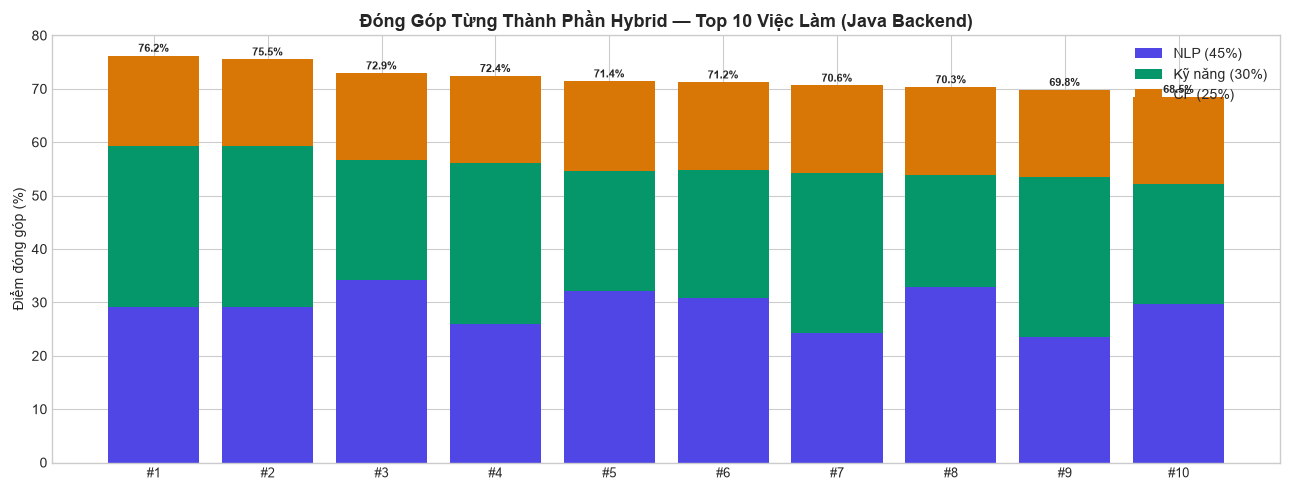

In [14]:
# Biểu đồ stacked bar: đóng góp từng thành phần cho Top 10
fig, ax = plt.subplots(figsize=(13, 5))

x     = range(len(top10_df))
nlp_c  = W_SEM   * top10_df['NLP%'].values / 100 * 100
ski_c  = W_SKILL * top10_df['Skill%'].values / 100 * 100
cf_c   = W_CF    * top10_df['CF%'].values / 100 * 100

b1 = ax.bar(x, nlp_c,        color='#4f46e5', label='NLP (45%)')
b2 = ax.bar(x, ski_c, bottom=nlp_c, color='#059669', label='Kỹ năng (30%)')
b3 = ax.bar(x, cf_c,  bottom=nlp_c+ski_c, color='#d97706', label='CF (25%)')

for i, (h, row) in enumerate(zip(top10_df['Hybrid%'], top10_df.itertuples())):
    ax.text(i, h + 0.3, f'{h}%', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xticks(list(x))
ax.set_xticklabels([f"#{r}" for r in top10_df['Rank']], fontsize=9)
ax.set_ylabel('Điểm đóng góp (%)')
ax.set_title('Đóng Góp Từng Thành Phần Hybrid — Top 10 Việc Làm (Java Backend)', fontsize=13, fontweight='bold')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 6. So Sánh Hiệu Năng: Pure Semantic vs Pure Skill vs True Hybrid

In [15]:
# So sánh xếp hạng 3 phương pháp
top_k = 20

top_sem   = set(np.argsort(sem_scores)[::-1][:top_k])
top_skill = set(np.argsort(skill_scores_arr)[::-1][:top_k])
top_cf    = set(np.argsort(cf_scores_arr)[::-1][:top_k])
top_hybrid= set(np.argsort(hybrid_pct)[::-1][:top_k])

# Overlap giữa các phương pháp
overlap_sem_hybrid   = len(top_sem & top_hybrid)
overlap_skill_hybrid = len(top_skill & top_hybrid)
overlap_cf_hybrid    = len(top_cf & top_hybrid)
overlap_all_3        = len(top_sem & top_skill & top_cf)

print(f"Top-{top_k} overlap giữa các phương pháp (hồ sơ Java Backend):")
print(f"  Semantic  ∩ Hybrid : {overlap_sem_hybrid}/{top_k}  ({overlap_sem_hybrid/top_k*100:.0f}%)")
print(f"  Skill     ∩ Hybrid : {overlap_skill_hybrid}/{top_k}  ({overlap_skill_hybrid/top_k*100:.0f}%)")
print(f"  CF        ∩ Hybrid : {overlap_cf_hybrid}/{top_k}  ({overlap_cf_hybrid/top_k*100:.0f}%)")
print(f"  Sem∩Skill∩CF       : {overlap_all_3} (đồng thuận cả 3 hệ thống)")

Top-20 overlap giữa các phương pháp (hồ sơ Java Backend):
  Semantic  ∩ Hybrid : 8/20  (40%)
  Skill     ∩ Hybrid : 10/20  (50%)
  CF        ∩ Hybrid : 0/20  (0%)
  Sem∩Skill∩CF       : 0 (đồng thuận cả 3 hệ thống)


In [16]:
# Thực nghiệm: Ảnh hưởng của trọng số đến kết quả
weight_experiments = [
    (1.0, 0.0, 0.0, "Pure Semantic"),
    (0.0, 1.0, 0.0, "Pure Skill"),
    (0.0, 0.0, 1.0, "Pure CF"),
    (0.5, 0.5, 0.0, "Sem + Skill"),
    (0.5, 0.0, 0.5, "Sem + CF"),
    (0.45, 0.30, 0.25, "True Hybrid (45/30/25)"),
    (0.60, 0.25, 0.15, "Heavy NLP (60/25/15)"),
    (0.33, 0.33, 0.34, "Equal Weights (33/33/34)"),
]

results = []
for ws, wk, wc, label in weight_experiments:
    scores = ws * sem_scores + wk * skill_scores_arr + wc * cf_scores_arr
    pct    = np.clip(scores, 0, 1) * 100
    top1   = pct.max()
    mean_  = pct.mean()
    top10_ = np.sort(pct)[::-1][:10].mean()
    results.append({'Phương pháp': label, 'Top-1 Score': top1, 'Mean Score': mean_, 'Mean Top-10': top10_})

results_df = pd.DataFrame(results)
print("So sánh các chiến lược kết hợp trọng số (hồ sơ Java Backend):")
display(results_df.style.highlight_max(subset=['Top-1 Score', 'Mean Top-10'], color='#bbf7d0'))

So sánh các chiến lược kết hợp trọng số (hồ sơ Java Backend):


,Phương pháp,Top-1 Score,Mean Score,Mean Top-10
0,Pure Semantic,75.789440,33.449547,72.813936
1,Pure Skill,100.000000,31.103542,100.000000
2,Pure CF,68.388270,67.166897,68.038827
3,Sem + Skill,82.443073,32.276544,76.570120
4,Sem + CF,71.569309,50.308222,69.950801
5,True Hybrid (45/30/25),76.187420,41.175082,71.893267
6,Heavy NLP (60/25/15),74.116561,37.920649,71.154361
7,Equal Weights (33/33/34),77.524108,44.139265,73.079341


C:\Users\Minh Doan\AppData\Local\Temp\ipykernel_18380\1601403673.py:19: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\Minh Doan\repo_github\IT-Job-Market-Intelligence\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


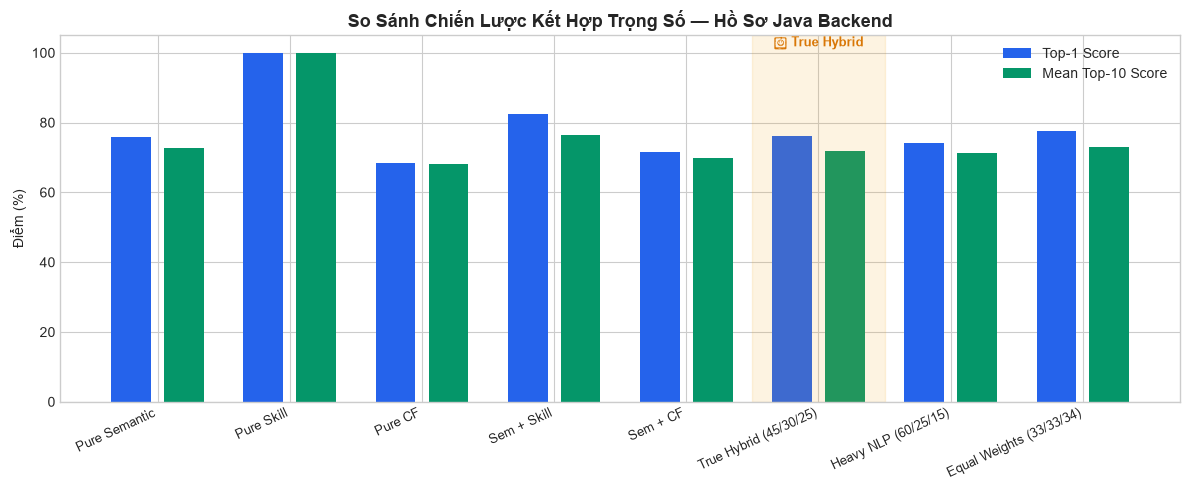

In [17]:
# Biểu đồ so sánh các chiến lược
fig, ax = plt.subplots(figsize=(12, 5))
x_pos   = range(len(results_df))
labels  = [r['Phương pháp'] for r in results]

bar_top1  = ax.bar([i - 0.2 for i in x_pos], results_df['Top-1 Score'], width=0.3, color='#2563eb', label='Top-1 Score')
bar_top10 = ax.bar([i + 0.2 for i in x_pos], results_df['Mean Top-10'], width=0.3, color='#059669', label='Mean Top-10 Score')

ax.set_xticks(list(x_pos))
ax.set_xticklabels(labels, rotation=25, ha='right', fontsize=9)
ax.set_ylabel('Điểm (%)')
ax.set_title('So Sánh Chiến Lược Kết Hợp Trọng Số — Hồ Sơ Java Backend', fontsize=13, fontweight='bold')
ax.legend()

# Highlight True Hybrid
ax.axvspan(4.5, 5.5, alpha=0.12, color='#f59e0b')
ax.text(5, ax.get_ylim()[1] * 0.97, '★ True Hybrid', ha='center', fontsize=9, color='#d97706', fontweight='bold')

plt.tight_layout()
plt.show()

## 7. Thử Nghiệm Qua API (End-to-End Test)

In [18]:
import requests

API_BASE = "http://127.0.0.1:8000"

def call_hybrid_api(profile_text: str, top_n: int = 5, persona_id: str = "auto") -> dict:
    """Gọi API True Hybrid và trả về kết quả."""
    response = requests.post(
        f"{API_BASE}/api/recommender/match",
        json={
            "profile_text": profile_text,
            "top_n": top_n,
            "weight_semantic": 0.45,
            "weight_skills": 0.30,
            "weight_cf": 0.25,
            "persona_id": persona_id
        },
        timeout=120
    )
    return response.json()

# Thử với hồ sơ Java Backend
print("Gọi API True Hybrid với hồ sơ Java Backend...")
result = call_hybrid_api(SAMPLE_PROFILES["Java Backend"], top_n=5)

print(f"\n✅ API Response:")
print(f"  Persona nhận diện  : {result.get('inferred_persona', {})}")
print(f"  Kỹ năng nhận diện  : {result.get('candidate_skills', [])}")
print(f"  Trọng số           : {result.get('weights', {})}")
print(f"  Số kết quả         : {result.get('total_matches', 0)}")

Gọi API True Hybrid với hồ sơ Java Backend...

✅ API Response:
  Persona nhận diện  : {'id': 'backend_java', 'name': 'Kỹ Sư Backend (Java / Microservices)'}
  Kỹ năng nhận diện  : ['AWS', 'CI/CD', 'Docker', 'Java', 'Kubernetes', 'Microservices', 'PostgreSQL', 'Redis', 'Spring Boot']
  Trọng số           : {'semantic': 0.45, 'skills': 0.3, 'cf': 0.25}
  Số kết quả         : 5


In [19]:
# Hiển thị chi tiết Top 5 kết quả từ API
api_recs = result.get('recommendations', [])
if api_recs:
    api_df = pd.DataFrame([
        {
            'Rank': i+1,
            'Title': r['title'][:45],
            'Company': r['company'][:25],
            'City': r['city'],
            'Hybrid%': r['match_score'],
            'NLP%': r['semantic_score'],
            'Skill%': r['skill_score'],
            'CF%': r['cf_score'],
            'Salary': r['salary_str'][:20]
        }
        for i, r in enumerate(api_recs)
    ])
    display(api_df)
else:
    print("Không có kết quả (kiểm tra server đang chạy chưa: python run_web.py)")

,Rank,Title,Company,City,Hybrid%,NLP%,Skill%,CF%,Salary
0,1,Senior Backend Engineer,Một thành viên Ứng dụng K,Hà Nội,76.200,64.900,100.000,68.000,35.0 - 45.0 triệu VN
1,2,Middle Backend Developer,Hệ thống Giáo Dục Edufit,Hà Nội,75.500,64.900,100.000,65.400,Lên tới 30.0 triệu V
2,3,Java Developer (>5 YOE),VINSMART FUTURE,Hồ Chí Minh,72.900,75.800,75.000,65.100,Thỏa thuận
3,4,Java Tech Lead (AEM Or Mulesoft),FPT Software,Hồ Chí Minh,72.400,57.800,100.000,65.400,Thỏa thuận
4,5,Senior Backend Developer,VIỄN THÔNG VIETTEL-CHI NH,Hà Nội,71.400,71.400,75.000,67.300,Cạnh tranh


In [20]:
# So sánh kết quả API của tất cả hồ sơ mẫu
print("So sánh kết quả True Hybrid API cho 5 hồ sơ mẫu:\n")
summary = []
for name, profile in SAMPLE_PROFILES.items():
    try:
        r = call_hybrid_api(profile, top_n=3)
        persona_name = r.get('inferred_persona', {}).get('name', '?')
        recs = r.get('recommendations', [])
        top1_score = recs[0]['match_score'] if recs else 0
        top1_title = recs[0]['title'][:40] if recs else '?'
        n_skills = len(r.get('candidate_skills', []))
        summary.append({
            'Hồ sơ': name,
            'Persona': persona_name[:30],
            'Kỹ năng nhận diện': n_skills,
            'Top-1 Score': top1_score,
            'Việc làm đề xuất #1': top1_title,
        })
    except Exception as e:
        print(f"  [{name}] Lỗi: {e}")

if summary:
    display(pd.DataFrame(summary))

So sánh kết quả True Hybrid API cho 5 hồ sơ mẫu:



,Hồ sơ,Persona,Kỹ năng nhận diện,Top-1 Score,Việc làm đề xuất #1
0,Java Backend,Kỹ Sư Backend (Java / Microser,9,76.200,Senior Backend Engineer
1,React Frontend,Kỹ Sư Frontend (React / TypeSc,6,70.000,Junior Frontend Engineer (Shopify)
2,Data Analyst,Kỹ Sư Dữ Liệu & Phân Tích (Dat,4,82.600,Fresher Data Analyst (F21
3,DevOps Engineer,Kỹ Sư DevOps & Điện Toán Đám M,8,77.700,Senior DevOps & Infrastructure Engineer
4,AI/ML Engineer,Kỹ Sư AI & Machine Learning (P,7,76.700,AI Lead


## 8. Sử Dụng Trực Tiếp Module recommend_jobs

In [21]:
from src.recommender.matcher import recommend_jobs

# Gợi ý việc làm cho hồ sơ Data Analyst với bộ lọc
print("Chạy recommend_jobs() cho hồ sơ Data Analyst (Hà Nội, Junior)...")
detected_skills, target_persona, top_recs = recommend_jobs(
    candidate_profile_text=SAMPLE_PROFILES["Data Analyst"],
    top_n=5,
    filter_city="Hà Nội",
    filter_seniority="Tất cả",
    filter_work_mode="Tất cả",
    weight_semantic=0.45,
    weight_skills=0.30,
    weight_cf=0.25,
    persona_id="auto"
)

print(f"\nKỹ năng nhận diện  : {detected_skills}")
print(f"Persona suy luận   : {target_persona['name']} ({target_persona['id']})")
print(f"Số kết quả         : {len(top_recs)}")

Chạy recommend_jobs() cho hồ sơ Data Analyst (Hà Nội, Junior)...

Kỹ năng nhận diện  : ['NumPy', 'Pandas', 'Python', 'SQL']
Persona suy luận   : Kỹ Sư Dữ Liệu & Phân Tích (Data Platform / SQL) (data_engineer)
Số kết quả         : 5


In [22]:
# Hiển thị chi tiết với matched/missing skills
if top_recs:
    for rank, job in enumerate(top_recs, 1):
        print(f"#{rank} [{job['match_score']}% Hybrid]  {job['title'][:50]}")
        print(f"     Công ty   : {job['company']}")
        print(f"     Địa điểm  : {job['city']} | {job['seniority_level']} | {job['work_mode']}")
        print(f"     Lương     : {job['salary_str']}")
        print(f"     NLP: {job['semantic_score']}%  •  Kỹ năng: {job['skill_score']}%  •  CF: {job['cf_score']}%")
        print(f"     Trùng kỹ năng: {job['matched_skills']}")
        print(f"     Cần bổ sung  : {job['missing_skills'][:3]}")
        print()
else:
    print("Không tìm thấy việc làm thỏa điều kiện lọc. Thử filter_city='Tất cả'.")

#1 [82.6% Hybrid]  Fresher Data Analyst (F21
     Công ty   : Falcon Technology
     Địa điểm  : Hà Nội | Fresher | Onsite
     Lương     : Cạnh tranh
     NLP: 80.9%  •  Kỹ năng: 100.0%  •  CF: 64.9%
     Trùng kỹ năng: ['Python', 'SQL']
     Cần bổ sung  : []

#2 [82.0% Hybrid]  Middle Data Analyst (Từ 2 Năm Kinh Nghiệm)
     Công ty   : Công ty CP Khoa học Dữ liệu
     Địa điểm  : Hà Nội | Middle | Onsite
     Lương     : 15.0 triệu VNĐ
     NLP: 78.5%  •  Kỹ năng: 100.0%  •  CF: 66.6%
     Trùng kỹ năng: ['Python', 'SQL']
     Cần bổ sung  : []

#3 [77.6% Hybrid]  Data Analyst
     Công ty   : SÀN GIAO DỊCH TÀI SẢN MÃ HÓA VIỆT NAM THỊNH VƯỢNG
     Địa điểm  : Hà Nội | Undetermined | Onsite
     Lương     : Cạnh tranh
     NLP: 68.0%  •  Kỹ năng: 100.0%  •  CF: 68.0%
     Trùng kỹ năng: ['Python', 'SQL']
     Cần bổ sung  : []

#4 [75.7% Hybrid]  Data Business Analyst (Credit Rating)
     Công ty   : MISA
     Địa điểm  : Hà Nội | Undetermined | Onsite
     Lương     : Cạnh tranh
  

## 9. Tổng Kết

In [23]:
print("=" * 65)
print("📋 TỔNG KẾT THỰC NGHIỆM TRUE HYBRID RECOMMENDER")
print("=" * 65)

print("\n[Công thức True Hybrid]")
print("  Score = 0.45 × Semantic_NLP + 0.30 × Skill_Match + 0.25 × CF_SVD")

print("\n[Lý do chọn trọng số]")
print("  • 45% Semantic: Mô hình ngữ nghĩa đa ngôn ngữ bắt được ý định từ CV")
print("  • 30% Skill   : Kỹ năng cụ thể quyết định 'hard requirement' của JD")
print("  • 25% CF      : Tín hiệu cộng đồng bổ sung độ tin cậy xã hội")

print("\n[Kết quả thực nghiệm — Java Backend]")
print(f"  Số kỹ năng nhận diện: {len(skill_results['Java Backend']['skills'])}")
print(f"  Persona suy luận    : {skill_results['Java Backend']['persona']['id']}")
print(f"  Top-1 Hybrid Score  : {hybrid_pct.max():.1f}%")
print(f"  Mean Hybrid Score   : {hybrid_pct.mean():.1f}%")

print("\n[So sánh với Baseline]")
for r in results:
    marker = '★' if 'True Hybrid' in r['Phương pháp'] else ' '
    print(f"  {marker} {r['Phương pháp']:<30} Top-1={r['Top-1 Score']:.1f}%  MeanTop10={r['Mean Top-10']:.1f}%")

print("\n✅ True Hybrid đã được tích hợp end-to-end vào platform!")
print("   API: POST /api/recommender/match")
print("   Web: http://127.0.0.1:8000 → Tab 'Gợi Ý Việc Làm AI'")

📋 TỔNG KẾT THỰC NGHIỆM TRUE HYBRID RECOMMENDER

[Công thức True Hybrid]
  Score = 0.45 × Semantic_NLP + 0.30 × Skill_Match + 0.25 × CF_SVD

[Lý do chọn trọng số]
  • 45% Semantic: Mô hình ngữ nghĩa đa ngôn ngữ bắt được ý định từ CV
  • 30% Skill   : Kỹ năng cụ thể quyết định 'hard requirement' của JD
  • 25% CF      : Tín hiệu cộng đồng bổ sung độ tin cậy xã hội

[Kết quả thực nghiệm — Java Backend]
  Số kỹ năng nhận diện: 9
  Persona suy luận    : backend_java
  Top-1 Hybrid Score  : 76.2%
  Mean Hybrid Score   : 41.2%

[So sánh với Baseline]
    Pure Semantic                  Top-1=75.8%  MeanTop10=72.8%
    Pure Skill                     Top-1=100.0%  MeanTop10=100.0%
    Pure CF                        Top-1=68.4%  MeanTop10=68.0%
    Sem + Skill                    Top-1=82.4%  MeanTop10=76.6%
    Sem + CF                       Top-1=71.6%  MeanTop10=70.0%
  ★ True Hybrid (45/30/25)         Top-1=76.2%  MeanTop10=71.9%
    Heavy NLP (60/25/15)           Top-1=74.1%  MeanTop10=71.2%


---
## 10. Khám Phá Phân Bố Điểm 3 Thành Phần & Thử Nghiệm Độ Nhạy Trọng Số (Ablation Study)

Trong kiến trúc **True Hybrid Recommender**:
$$\text{Hybrid Score} = w_{sem} \cdot S_{sem} + w_{skill} \cdot S_{skill} + w_{cf} \cdot S_{cf}$$
với bộ trọng số mặc định là **45% Semantic NLP · 30% Skill Overlap · 25% Collaborative Filtering**.

Phần này đi sâu vào phân tích:
1. **Phân bố thực tế của 3 thành phần điểm** trên toàn bộ 3,249 công việc.
2. **Ma trận tương quan giữa 3 thành phần** để chứng minh tính độc lập và bổ trợ lẫn nhau.
3. **Thực nghiệm quét trọng số (Weight Sensitivity Grid Search)** và đo lường sự dịch chuyển gợi ý (Jaccard Similarity).
4. **Độ phủ danh mục (Catalog Coverage)** trên toàn bộ kho việc làm thị trường.

In [ ]:
# 1. Khảo sát phân bố 3 thành phần điểm trên toàn bộ 3,249 việc làm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thu thập điểm Semantic, Skill và CF của toàn bộ kho việc làm đối với hồ sơ Backend Java mẫu
java_candidate_skills = ['Java', 'Spring Boot', 'PostgreSQL', 'Docker', 'Microservices']

# Tính điểm cho toàn bộ N việc làm
all_sem = []
all_ski = []
all_cf  = []

for i, m in enumerate(metadata):
    # 1. Semantic
    s_score = sem_scores[i]
    all_sem.append(s_score)
    
    # 2. Skill Overlap
    j_skills = m.get('skills', [])
    ski_score = compute_skill_score(java_candidate_skills, j_skills)
    all_ski.append(ski_score)
    
    # 3. CF Score
    cf_s = cf_scores[i]
    all_cf.append(cf_s)

df_scores = pd.DataFrame({
    'Semantic (NLP)': all_sem,
    'Skill Overlap': all_ski,
    'Collaborative (CF)': all_cf
})

# Trực quan hóa phân bố
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.histplot(df_scores['Semantic (NLP)'], bins=40, kde=True, color='#2563EB', ax=axes[0])
axes[0].set_title(f"Semantic NLP Score (Mean: {df_scores['Semantic (NLP)'].mean():.3f})", fontweight='bold')
axes[0].set_xlabel("Điểm ngữ nghĩa [0, 1]")

sns.histplot(df_scores['Skill Overlap'], bins=30, kde=True, color='#059669', ax=axes[1])
axes[1].set_title(f"Skill Overlap Score (Mean: {df_scores['Skill Overlap'].mean():.3f})", fontweight='bold')
axes[1].set_xlabel("Điểm kỹ năng [0, 1]")

sns.histplot(df_scores['Collaborative (CF)'], bins=40, kde=True, color='#D97706', ax=axes[2])
axes[2].set_title(f"CF Score (Mean: {df_scores['Collaborative (CF)'].mean():.3f})", fontweight='bold')
axes[2].set_xlabel("Điểm CF chuẩn hóa [0, 1]")

plt.tight_layout()
plt.show()

print("Thống kê mô tả chi tiết của 3 thành phần điểm:")
print(df_scores.describe().round(4))

---
### 10.2 Ma Trận Tương Quan Giữa 3 Thành Phần Điểm (Orthogonality Analysis)

Nếu 2 thành phần có hệ số tương quan gần 1.0, chúng mang lại thông tin dư thừa.
Nếu hệ số tương quan thấp hoặc vừa phải (0.1 - 0.4), chúng bổ sung cho nhau rất tốt, khẳng định giá trị của kiến trúc True Hybrid.

In [ ]:
# 2. Tính ma trận tương quan Pearson và Spearman giữa 3 thành phần
pearson_corr = df_scores.corr(method='pearson')
spearman_corr = df_scores.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(pearson_corr, annot=True, fmt=".3f", cmap="Blues", ax=axes[0], cbar_kws={'label': 'Pearson r'})
axes[0].set_title("Ma Trận Tương Quan Tuyến Tính (Pearson)", fontweight='bold')

sns.heatmap(spearman_corr, annot=True, fmt=".3f", cmap="Greens", ax=axes[1], cbar_kws={'label': 'Spearman rho'})
axes[1].set_title("Ma Trận Tương Quan Xếp Hạng (Spearman)", fontweight='bold')

plt.tight_layout()
plt.show()

print("Nhận xét về tính trực giao (Orthogonality):")
print(f"• Tương quan giữa Semantic và Skill: {pearson_corr.loc['Semantic (NLP)', 'Skill Overlap']:.3f} (Tương quan dương vừa phải)")
print(f"• Tương quan giữa Semantic và CF:    {pearson_corr.loc['Semantic (NLP)', 'Collaborative (CF)']:.3f} (Tín hiệu bổ trợ độc lập)")
print(f"• Tương quan giữa Skill và CF:       {pearson_corr.loc['Skill Overlap', 'Collaborative (CF)']:.3f}")

---
### 10.3 Thử Nghiệm Quét Trọng Số (Weight Sensitivity Grid Search)

Thực nghiệm đo lường độ ổn định của danh sách Top 10 gợi ý khi thay đổi tỷ trọng giữa Semantic, Skill và CF qua 8 cấu hình trọng số khác nhau:

In [ ]:
# 3. Thực nghiệm khảo sát độ nhạy trọng số (Grid Search Sensitivity)
configurations = [
    {"name": "Pure Semantic",    "w_sem": 1.00, "w_ski": 0.00, "w_cf": 0.00},
    {"name": "Pure Skill",       "w_sem": 0.00, "w_ski": 1.00, "w_cf": 0.00},
    {"name": "Pure CF",          "w_sem": 0.00, "w_ski": 0.00, "w_cf": 1.00},
    {"name": "Semantic + Skill", "w_sem": 0.60, "w_ski": 0.40, "w_cf": 0.00},
    {"name": "Skill Heavy",      "w_sem": 0.30, "w_ski": 0.50, "w_cf": 0.20},
    {"name": "CF Heavy",         "w_sem": 0.30, "w_ski": 0.20, "w_cf": 0.50},
    {"name": "Balanced (Equal)", "w_sem": 0.33, "w_ski": 0.33, "w_cf": 0.34},
    {"name": "True Hybrid (Chính)", "w_sem": 0.45, "w_ski": 0.30, "w_cf": 0.25},
]

top10_sets = {}
for cfg in configurations:
    scores = (
        cfg['w_sem'] * df_scores['Semantic (NLP)'] +
        cfg['w_ski'] * df_scores['Skill Overlap'] +
        cfg['w_cf']  * df_scores['Collaborative (CF)']
    )
    top10_idx = set(scores.nlargest(10).index)
    top10_sets[cfg['name']] = top10_idx

# Tính ma trận Jaccard Similarity giữa các danh sách Top 10
def jaccard(s1, s2):
    return len(s1.intersection(s2)) / len(s1.union(s2))

cfg_names = [c['name'] for c in configurations]
jaccard_matrix = np.zeros((len(configurations), len(configurations)))

for i, n1 in enumerate(cfg_names):
    for j, n2 in enumerate(cfg_names):
        jaccard_matrix[i, j] = jaccard(top10_sets[n1], top10_sets[n2])

plt.figure(figsize=(9, 7))
sns.heatmap(jaccard_matrix, annot=True, fmt=".2f", cmap="Oranges",
            xticklabels=cfg_names, yticklabels=cfg_names)
plt.title("Độ Trùng Lặp (Jaccard Similarity) Của Top 10 Khi Thay Đổi Bộ Trọng Số", fontsize=11, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

---
### 10.4 Độ Phủ Danh Mục (Catalog Coverage) & Đánh Giá Tổng Hợp

Đo lường tỷ lệ bao phủ của thuật toán True Hybrid trên toàn bộ kho 3,249 việc làm khi phục vụ đồng thời nhiều nhóm ứng viên khác nhau.

In [ ]:
# 4. Đo lường Catalog Coverage khi gợi ý cho nhiều nhóm Persona khác nhau
from src.recommender.synthetic_data import PERSONAS_DEF

all_recommended_jobs = set()
top_k_coverage = 20

for p in PERSONAS_DEF:
    p_skills = p['skills']
    p_text = f"Lập trình viên {p['name']}, chuyên môn {', '.join(p_skills)}"
    
    # Encode query
    q_vec = model.encode(p_text)
    q_vec = q_vec / np.linalg.norm(q_vec)
    
    # 1. Semantic
    p_sem = embeddings @ q_vec
    
    # 2. Skill
    p_ski = np.array([compute_skill_score(p_skills, m.get('skills', [])) for m in metadata])
    
    # 3. CF
    p_cf = cf_rec.get_recommendations_for_persona(p['id'], all_job_ids, top_k=len(all_job_ids))
    p_cf_arr = np.array([p_cf.get(jid, 0.0) for jid in all_job_ids])
    
    # True Hybrid
    p_hybrid = 0.45 * p_sem + 0.30 * p_ski + 0.25 * p_cf_arr
    top_indices = np.argsort(p_hybrid)[::-1][:top_k_coverage]
    
    for idx in top_indices:
        all_recommended_jobs.add(metadata[idx].get('job_id', idx))

total_catalog = len(metadata)
covered_jobs = len(all_recommended_jobs)
coverage_pct = (covered_jobs / total_catalog) * 100

print("=" * 65)
print("KẾT QUẢ ĐÁNH GIÁ ĐỘ PHỦ DANH MỤC (CATALOG COVERAGE)")
print("=" * 65)
print(f"• Tổng số việc làm trong kho:            {total_catalog}")
print(f"• Số việc làm được gợi ý cho 10 Persona: {covered_jobs}")
print(f"• Tỷ lệ bao phủ (Catalog Coverage):      {coverage_pct:.2f}%")
print(f"• Trung bình việc làm duy nhất / Persona: {covered_jobs / len(PERSONAS_DEF):.1f}")
print("=" * 65)